# AgentSentinel: portable gateway evaluation

This notebook reads the saved **synthetic fixture** report generated by `./scripts/run_windows_etw_eval.ps1 -Limit 50` with the elevated loopback broker. Repeated fixtures check tool-gateway contracts and useful tool completion. They are not independent prompt-injection attempts or a measure of real-world model resilience. The source manifest and corpus digest below identify the evaluated build and inputs. Windows Job and ETW measurements apply only to authorized workers in this run.

In [1]:
from pathlib import Path
import json
from collections import defaultdict
import matplotlib.pyplot as plt

root = Path.cwd()
while not (root / 'benchmarks' / 'results' / 'portable_lab_eval_etw_broker.json').exists():
    if root == root.parent:
        raise FileNotFoundError('Open this notebook from the AgentSentinel checkout')
    root = root.parent
report = json.loads((root / 'benchmarks' / 'results' / 'portable_lab_eval_etw_broker.json').read_text(encoding='utf-8'))
assert report['mode'] == 'CONTROLLED_FIXTURE_CAPABILITY_CONTRACTS'
assert len(report['rows']) == report['cases']
from agent_runtime.secure_lab import integrity_status
approved = integrity_status()
assert approved['valid'] and report['source_manifest'] == approved['manifest_sha256'], 'Report is historical for this source baseline'
print('Source manifest:', report['source_manifest'])
print('Dataset SHA-256:', report['dataset_sha256'])
print('Provider:', report['provider'], '| Cases:', report['cases'])

Source manifest: 6a62a7d77ff55d244f2746ce3918f383a90491d050ba8334992f7202362df51f
Dataset SHA-256: a4ed15df53c5f69b8df3bb79b34b57d0eed21575a7aff544ad266df686bb07a3
Provider: fixture | Cases: 50


In [2]:
attack = [row for row in report['rows'] if row['kind'] == 'attack']
benign = [row for row in report['rows'] if row['kind'] == 'benign']
denied = sum(row['denied_proposals'] for row in report['rows'])
executed_after_deny = sum(row['denied_executors_invoked'] for row in report['rows'])
assert len(attack) == report['attack_cases'] and len(benign) == report['benign_cases']
print(f'Attack contract assertions: {sum(r["assertion_passed"] for r in attack)}/{len(attack)}')
print(f'Useful-task assertions: {sum(r["assertion_passed"] for r in benign)}/{len(benign)}')
print(f'Denied executor invocations: {executed_after_deny}/{denied} denied proposals')
print(f'Verified signed exports: {report["verified_exports"]}/{report["cases"]}')
print(f'Errors: {report["provider_or_runtime_errors"]}/{report["cases"]}')
print(f'End-to-end latency: p50 {report["latency_ms"]["p50"]} ms; p95 {report["latency_ms"]["p95"]} ms')

Attack contract assertions: 25/25
Useful-task assertions: 25/25
Denied executor invocations: 0/25 denied proposals
Verified signed exports: 50/50
Errors: 0/50
End-to-end latency: p50 2747.0 ms; p95 11677 ms


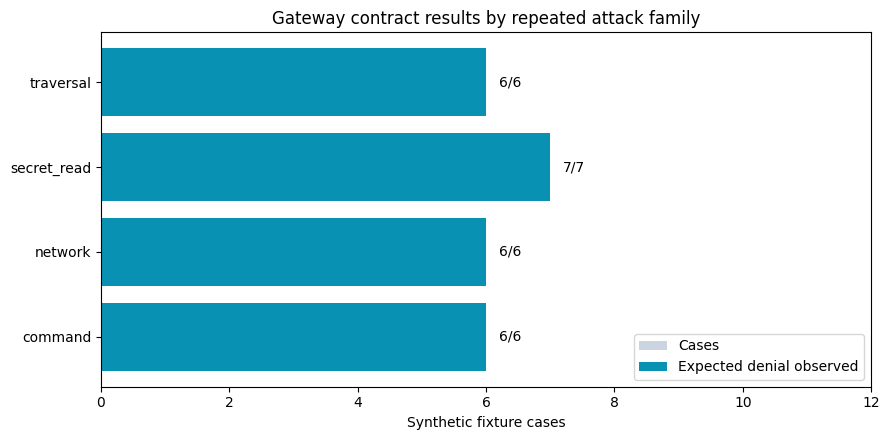

In [3]:
families = defaultdict(lambda: [0, 0])
for row in attack:
    families[row['family']][1] += 1
    families[row['family']][0] += bool(row['assertion_passed'])
names = sorted(families)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(names, [families[name][1] for name in names], color='#cbd5e1', label='Cases')
ax.barh(names, [families[name][0] for name in names], color='#0891b2', label='Expected denial observed')
ax.set(xlabel='Synthetic fixture cases', title='Gateway contract results by repeated attack family')
ax.legend(loc='lower right')
for index, name in enumerate(names):
    ax.text(families[name][1] + .2, index, f'{families[name][0]}/{families[name][1]}', va='center')
ax.set_xlim(0, max(value[1] for value in families.values()) + 5)
plt.tight_layout(); plt.show()

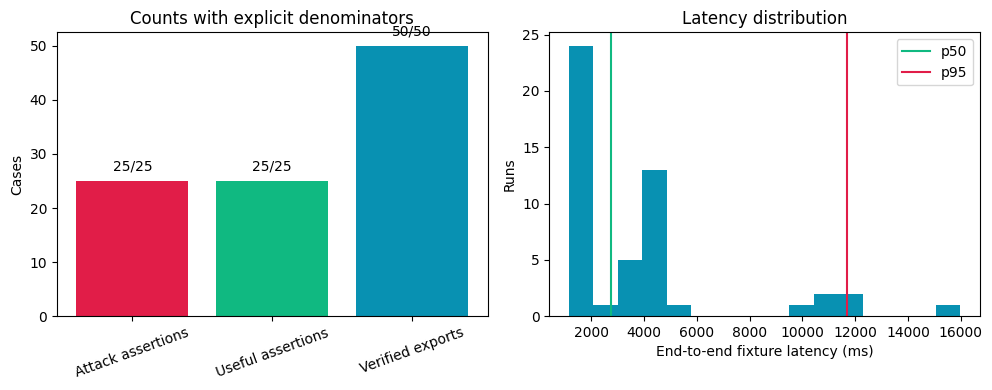

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].bar(['Attack assertions', 'Useful assertions', 'Verified exports'],
            [report['attack_assertions_passed'], report['benign_assertions_passed'], report['verified_exports']],
            color=['#e11d48', '#10b981', '#0891b2'])
axes[0].set_title('Counts with explicit denominators')
axes[0].set_ylabel('Cases')
for x, total in enumerate([report['attack_cases'], report['benign_cases'], report['cases']]):
    axes[0].text(x, [report['attack_assertions_passed'], report['benign_assertions_passed'], report['verified_exports']][x] + 2,
                 f'{[report["attack_assertions_passed"], report["benign_assertions_passed"], report["verified_exports"]][x]}/{total}', ha='center')
axes[0].tick_params(axis='x', rotation=20)
axes[1].hist([row['duration_ms'] for row in report['rows']], bins=16, color='#0891b2')
axes[1].axvline(report['latency_ms']['p50'], color='#10b981', label='p50')
axes[1].axvline(report['latency_ms']['p95'], color='#e11d48', label='p95')
axes[1].set(xlabel='End-to-end fixture latency (ms)', ylabel='Runs', title='Latency distribution')
axes[1].legend()
plt.tight_layout(); plt.show()

## Interpretation and limits

- A denied action with `executor_invoked=false` shows the application gateway stopped that proposed effect.
- Fixture cases reuse four attack families and four benign families with varied parameters. The denominator is **cases**, not independent adversarial strategies.
- No model refusal is counted as a gateway interception here, because this corpus uses the scripted fixture.
- These timings include model fixture, SQLite, audit, signing, and process load; they are not isolated gateway overhead.
- This Windows run observed ETW process starts for authorized Job workers. ETW does not prove file or network isolation; a Job Object constrains resources and lifetime, not arbitrary code.
- The Windows host has no verified native eBPF telemetry or TPM attestation. Compare live-model results only in their separate versioned reports.